# Advertising Regression from First Principles

## Objective

The same advertising problem is solved three times: TV versus Sales, Radio
versus Sales, and Newspaper versus Sales. The notebook constructs the design
matrix manually, learns the parameters with NumPy, and evaluates predictions
on data that was not used for fitting.

## Reading the results

- The slope measures the expected change in Sales for one additional unit of
  advertising budget.
- The intercept is the model's baseline prediction when the feature is zero.
- A lower MSE is better; an $R^2$ closer to $1$ means that more target
  variation is explained by the feature.

The cost curve should decrease and then stabilise. If it diverges, the learning
rate is too large for the scale of the feature.

## Mathematical foundations

For a linear model, the prediction is the weighted sum of the input features:

$$
\hat{y} = X\theta
$$

The notebooks add a column of ones to $X$ when the intercept is learned as one
of the parameters in $\theta$. The objective is the half mean-squared error:

$$
J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}(\hat{y}^{(i)}-y^{(i)})^2
$$

Its gradient is:

$$
\nabla_\theta J(\theta) = \frac{1}{m}X^T(X\theta-y)
$$

Gradient descent repeatedly updates the parameters in the direction that
reduces the cost:

$$
\theta \leftarrow \theta - \alpha\nabla_\theta J(\theta)
$$

where $m$ is the number of observations and $\alpha$ is the learning rate.
Model quality is reported with mean squared error and the coefficient of
determination:

$$
\mathrm{MSE}=\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2,
\qquad
R^2=1-\frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y})^2}
$$


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.metrics import mean_squared_error , r2_score
from sklearn.preprocessing import StandardScaler

In [24]:
df = pd.read_csv("data/Advertising.csv")
df

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,14.0
197,177.0,9.3,6.4,14.8
198,283.6,42.0,66.2,25.5


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


# *MODEL 1   , TV vs Sales*


In [26]:
x  = df.TV
y = df.Sales

In [27]:
x

,TV
0,230.1
1,44.5
2,17.2
3,151.5
4,180.8
...,...
195,38.2
196,94.2
197,177.0
198,283.6


<Axes: xlabel='TV', ylabel='Sales'>

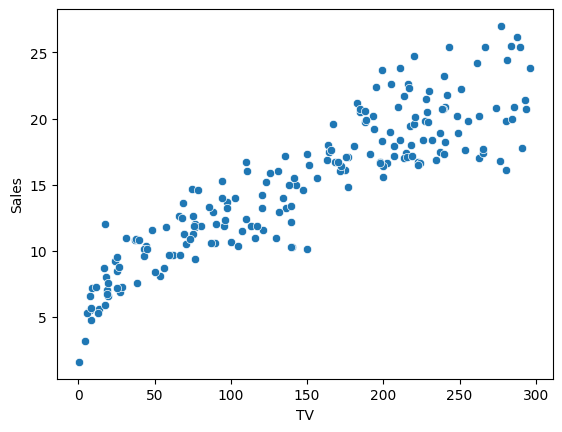

In [28]:
sns.scatterplot(x = x , y = y)

In [29]:
x.shape

(200,)

In [30]:
y.shape

(200,)

In [31]:
x=df.TV.values.reshape(200,1)
y=df.Sales.values.reshape(200,1)
print(x.shape)
print(y.shape)

(200, 1)
(200, 1)


In [32]:
X=np.hstack((x,(np.ones(x.shape))))

In [33]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(160, 1)
(40, 1)
(160, 1)
(40, 1)


In [34]:
X_train=np.hstack((x_train,(np.ones(x_train.shape))))
X_test=np.hstack((x_test,(np.ones(x_test.shape))))
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(160, 2)
(40, 2)
(160, 1)
(40, 1)


In [35]:
print(X_train.dtype)
print(X_test.dtype)
print(y_train.dtype)
print(y_test.dtype)

float64
float64
float64
float64


In [36]:
np.random.seed(0)
theta = np.random.rand(2,1)
print(theta)

[[0.5488135 ]
 [0.71518937]]


In [37]:
def model(X , theta) :
  return X.dot(theta)

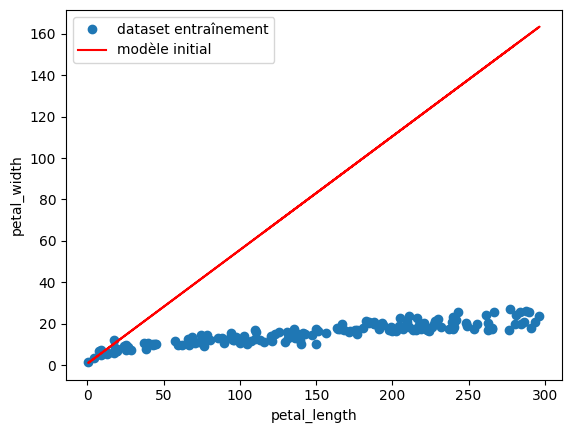

In [38]:
plt.plot(x_train,y_train,'o',label='dataset entraÃ®nement')
plt.plot(x_train, model(X_train, theta), c='r',label='modÃ¨le initial')
plt.xlabel('petal_length')
plt.ylabel('petal_width')
plt.legend()
plt.show()

In [39]:
def cost_function(X, y, theta):
    m = len(y)
    return 1/(2*m) * np.sum((model(X, theta) - y)**2)


cost_function(X_train, y_train, theta)

np.float64(3157.1016995508203)

In [40]:
def grad(X, y, theta):
    m = len(y)
    return 1/m * X.T.dot(model(X, theta) - y)

In [41]:
def gradient_descent(X, y, theta, learning_rate, n_iterations):

    cost_history = np.zeros(n_iterations) # crÃ©ation d'un tableau de stockage pour enregistrer l'Ã©volution du Cout du modele

    for i in range(0, n_iterations):
        theta = theta - learning_rate * grad(X, y, theta) # mise a jour du parametre theta (formule du gradient descent)
        cost_history[i] = cost_function(X, y, theta) # on enregistre la valeur du Cout au tour i dans cost_history[i]

    return theta, cost_history

In [42]:
n_iterations = 10*10**5
learning_rate = 0.00001


theta_final, cost_history = gradient_descent(X_train, y_train, theta, learning_rate, n_iterations)
cost_history

array([1568.86882092,  781.45969443,  391.08045597, ...,    2.53875266,
          2.53875248,    2.53875229])

In [43]:
theta_final

array([[0.05839702],
       [6.4323797 ]])

Text(0.5, 1.0, 'Cost Function')

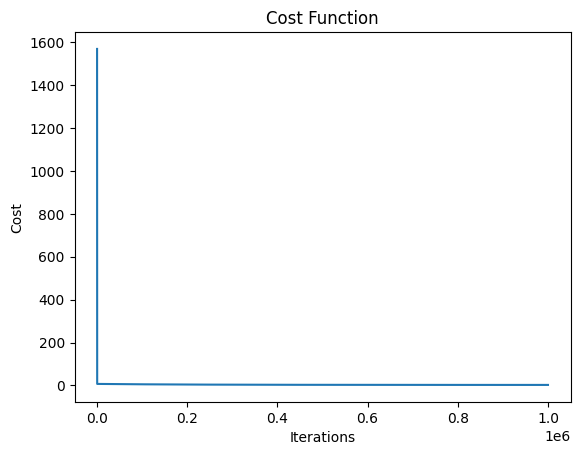

In [44]:
plt.plot(cost_history)
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title("Cost Function")

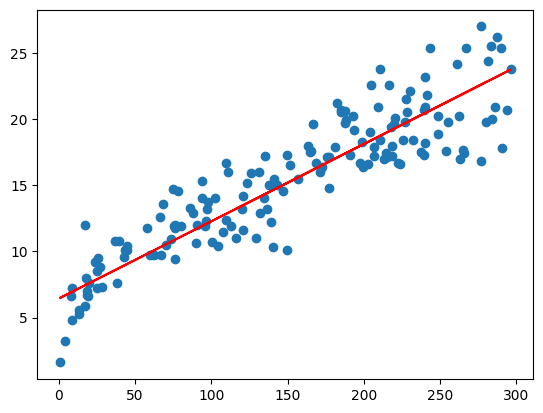

In [45]:
plt.plot(x_train,y_train,'o',label='dataset entraÃ®nement')
plt.plot(x_train, model(X_train, theta_final), c='r',label='modÃ¨le final')

In [46]:
y_pred = model(X_test, theta_final)

In [47]:
y_pred

array([[15.96861305],
       [17.84315739],
       [23.53686683],
       [ 7.11562484],
       [19.29724319],
       [10.8179959 ],
       [19.09285362],
       [ 9.3522307 ],
       [19.41987693],
       [16.65769789],
       [ 8.27188583],
       [ 9.71429222],
       [20.12648087],
       [ 6.74772361],
       [14.57876398],
       [16.37155249],
       [ 6.85867795],
       [17.97163084],
       [10.8296753 ],
       [20.29583223],
       [19.83449577],
       [10.39169765],
       [ 8.65146646],
       [21.084192  ],
       [10.46177408],
       [ 9.55662027],
       [18.90014345],
       [14.56708458],
       [11.52459984],
       [ 6.92291467],
       [18.10010428],
       [10.47345348],
       [18.04754696],
       [ 7.41928934],
       [22.82442319],
       [20.34254984],
       [ 9.25295576],
       [22.41564405],
       [13.27651044],
       [ 8.03829775]])

In [48]:
r_score = r2_score(y_test, y_pred)
r_score

0.8007867219387818

In [49]:
error = mean_squared_error(y_test, y_pred)
error

6.15590942669751

# *MODEL 2, Radio vs Sales*


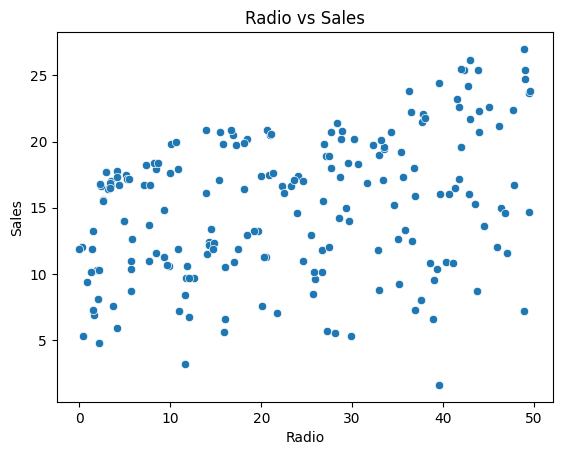

In [50]:
x_radio = df.Radio
y_radio = df.Sales

sns.scatterplot(x=x_radio, y=y_radio)
plt.title('Radio vs Sales')
plt.xlabel('Radio')
plt.ylabel('Sales')
plt.show()

In [51]:
x_radio = df.Radio.values.reshape(-1, 1)
y_radio = df.Sales.values.reshape(-1, 1)

print(x_radio.shape)
print(y_radio.shape)

(200, 1)
(200, 1)


In [52]:
x_train_radio, x_test_radio, y_train_radio, y_test_radio = train_test_split(x_radio, y_radio, test_size=0.2, random_state=42)

print(x_train_radio.shape)
print(x_test_radio.shape)
print(y_train_radio.shape)
print(y_test_radio.shape)

(160, 1)
(40, 1)
(160, 1)
(40, 1)


In [53]:
X_train_radio = np.hstack((x_train_radio, (np.ones(x_train_radio.shape))))
X_test_radio = np.hstack((x_test_radio, (np.ones(x_test_radio.shape))))

print(X_train_radio.shape)
print(X_test_radio.shape)

(160, 2)
(40, 2)


In [54]:
np.random.seed(0) # Use the same seed for reproducibility
theta_radio = np.random.rand(2,1)
print(theta_radio)

[[0.5488135 ]
 [0.71518937]]


In [55]:
cost_function(X_train_radio, y_train_radio, theta_radio)

np.float64(33.981934936466125)

In [56]:
n_iterations_radio = 10*10**6
learning_rate_radio = 0.00001 # May need to adjust learning rate for 'Radio'

theta_final_radio, cost_history_radio = gradient_descent(X_train_radio, y_train_radio, theta_radio, learning_rate_radio, n_iterations_radio)
cost_history_radio

array([33.96057209, 33.93952323, 33.9187837 , ..., 11.8313214 ,
       11.8313214 , 11.8313214 ])

In [57]:
theta_final_radio

array([[ 0.12000114],
       [12.58552398]])

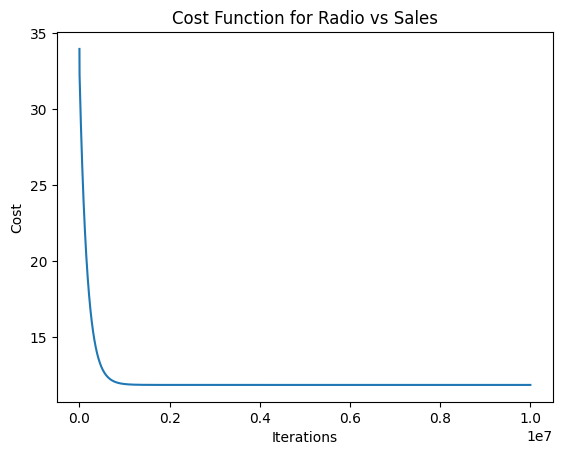

In [58]:
plt.plot(cost_history_radio)
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title('Cost Function for Radio vs Sales')
plt.show()

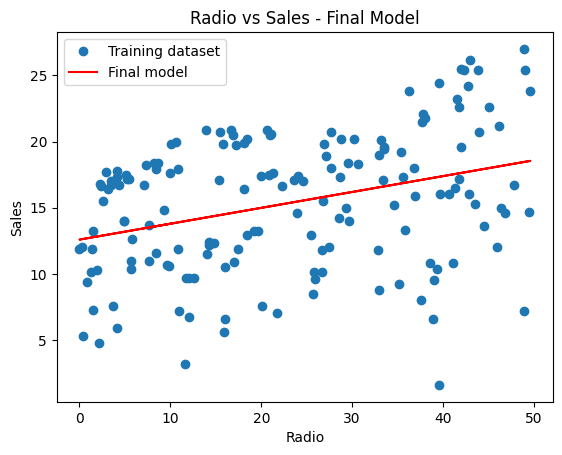

In [59]:
plt.plot(x_train_radio, y_train_radio, 'o', label='Training dataset')
plt.plot(x_train_radio, model(X_train_radio, theta_final_radio), c='r', label='Final model')
plt.xlabel('Radio')
plt.ylabel('Sales')
plt.legend()
plt.title('Radio vs Sales - Final Model')
plt.show()

In [60]:
y_pred_radio = model(X_test_radio, theta_final_radio)
y_pred_radio

array([[16.37755992],
       [18.30957824],
       [15.98155617],
       [17.01356595],
       [18.46557972],
       [16.78556379],
       [17.85357392],
       [13.97753717],
       [12.99352785],
       [15.28554957],
       [15.53755196],
       [13.26953046],
       [12.99352785],
       [16.17355799],
       [12.83752637],
       [13.52153285],
       [15.95755594],
       [15.38155048],
       [15.02154707],
       [15.88555526],
       [16.46156072],
       [16.97756561],
       [17.42156982],
       [16.9655655 ],
       [13.70153456],
       [12.82552625],
       [17.74557289],
       [14.32554047],
       [14.0015374 ],
       [15.84955492],
       [12.89752694],
       [15.0455473 ],
       [18.51358017],
       [17.82957369],
       [14.25353979],
       [16.701563  ],
       [18.22557744],
       [16.05355685],
       [14.3495407 ],
       [12.7775258 ]])

In [61]:
r_score_radio = r2_score(y_test_radio, y_pred_radio)
print(f'R-squared for Radio vs Sales: {r_score_radio}')

R-squared for Radio vs Sales: 0.10697088620527062


In [62]:
error_radio = mean_squared_error(y_test_radio, y_pred_radio)
print(f'Mean Squared Error for Radio vs Sales: {error_radio}')

Mean Squared Error for Radio vs Sales: 27.59558194828231


# *MODEL 3, Newspaper vs Sales*


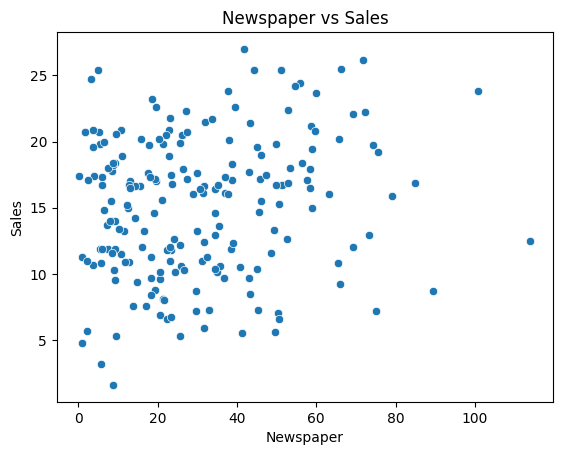

In [63]:
x_newspaper = df.Newspaper
y_newspaper = df.Sales

sns.scatterplot(x=x_newspaper, y=y_newspaper)
plt.title('Newspaper vs Sales')
plt.xlabel('Newspaper')
plt.ylabel('Sales')
plt.show()

In [64]:
x_newspaper = df.Newspaper.values.reshape(-1, 1)
y_newspaper = df.Sales.values.reshape(-1, 1)

print(x_newspaper.shape)
print(y_newspaper.shape)

(200, 1)
(200, 1)


In [65]:
x_train_newspaper, x_test_newspaper, y_train_newspaper, y_test_newspaper = train_test_split(x_newspaper, y_newspaper, test_size=0.2, random_state=42)

print(x_train_newspaper.shape)
print(x_test_newspaper.shape)
print(y_train_newspaper.shape)
print(y_test_newspaper.shape)

(160, 1)
(40, 1)
(160, 1)
(40, 1)


In [66]:
X_train_newspaper = np.hstack((x_train_newspaper, (np.ones(x_train_newspaper.shape))))
X_test_newspaper = np.hstack((x_test_newspaper, (np.ones(x_test_newspaper.shape))))

print(X_train_newspaper.shape)
print(X_test_newspaper.shape)

(160, 2)
(40, 2)


In [67]:
np.random.seed(0) # Use the same seed for reproducibility
theta_newspaper = np.random.rand(2,1)
print(theta_newspaper)

[[0.5488135 ]
 [0.71518937]]


In [68]:
cost_function(X_train_newspaper, y_train_newspaper, theta_newspaper)

np.float64(68.56321387211807)

In [69]:
n_iterations_newspaper = 10*10**5
learning_rate_newspaper = 0.001 # May need to adjust learning rate for 'Newspaper'

theta_final_newspaper, cost_history_newspaper = gradient_descent(X_train_newspaper, y_train_newspaper, theta_newspaper, learning_rate_newspaper, n_iterations_newspaper)
cost_history_newspaper

array([44.31243194, 41.98945389, 41.75222358, ..., 13.1157091 ,
       13.1157091 , 13.1157091 ])

In [70]:
theta_final_newspaper

array([[ 0.03717439],
       [14.21741479]])

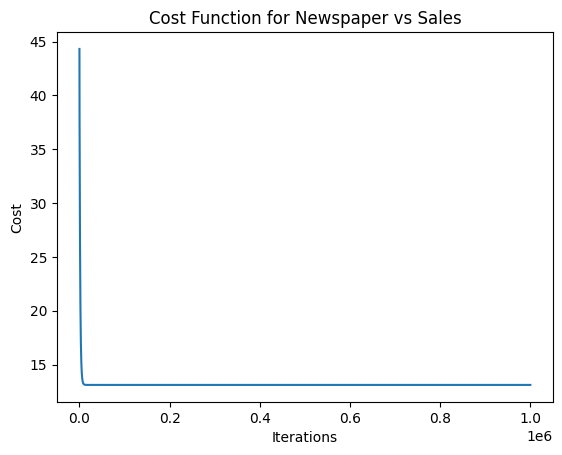

In [71]:
plt.plot(cost_history_newspaper)
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title('Cost Function for Newspaper vs Sales')
plt.show()

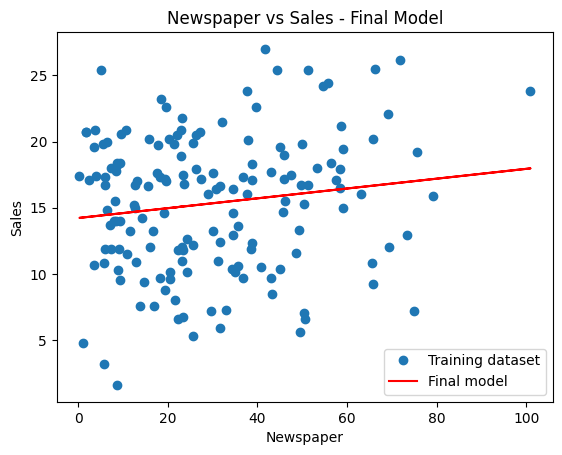

In [72]:
plt.plot(x_train_newspaper, y_train_newspaper, 'o', label='Training dataset')
plt.plot(x_train_newspaper, model(X_train_newspaper, theta_final_newspaper), c='r', label='Final model')
plt.xlabel('Newspaper')
plt.ylabel('Sales')
plt.legend()
plt.title('Newspaper vs Sales - Final Model')
plt.show()

In [73]:
y_pred_newspaper = model(X_test_newspaper, theta_final_newspaper)
y_pred_newspaper

array([[16.18393979],
       [16.18393979],
       [15.82334825],
       [15.89769702],
       [14.33637283],
       [16.17650491],
       [15.22855808],
       [14.90142349],
       [14.70439924],
       [15.38840794],
       [14.29919844],
       [15.32149404],
       [17.36980268],
       [14.56685402],
       [15.20625345],
       [15.52595316],
       [15.75643435],
       [14.74529107],
       [15.42558232],
       [14.62633303],
       [16.9757542 ],
       [18.45529474],
       [14.65978998],
       [16.90512286],
       [14.25087174],
       [15.01294664],
       [15.47390902],
       [14.59659352],
       [15.18023138],
       [14.295481  ],
       [15.00551176],
       [14.89770605],
       [16.44787792],
       [17.54080486],
       [15.59286706],
       [14.41443903],
       [14.53339707],
       [16.43672561],
       [14.41815647],
       [14.98692457]])

In [74]:
r_score_newspaper = r2_score(y_test_newspaper, y_pred_newspaper)
print(f'R-squared for Newspaper vs Sales: {r_score_newspaper}')

R-squared for Newspaper vs Sales: 0.004586344085894423


In [75]:
error_newspaper = mean_squared_error(y_test_newspaper, y_pred_newspaper)
print(f'Mean Squared Error for Newspaper vs Sales: {error_newspaper}')

Mean Squared Error for Newspaper vs Sales: 30.759376922767366
